# Задача 7: Методи регресійного аналізу в Python

Загальна мета полягає в тому, щоб пояснити ціни продажу SalePrice за допомогою набору змінних, використовуючи набір даних із попереднього домашнього завдання (Ames Housing). Змінна SalePrice приймається як залежна змінна (target), а решта змінних – як пояснювальні (features).

***Answer***

[Оригінальна умова](../input/assignment_4.pdf). Використовуємо повний Ames Housing; клас 1 означає ціну **строго більшу** за 130000 доларів США, клас 0 ціну не більшу за цей поріг. Вислови «дорогий» та «доступний» нижче стосуються лише цього умовного поділу, а не платоспроможності конкретного покупця.

Відбір починаємо лише з числових ознак. Вилучаємо `SalePrice` (визначає відповідь), `Order` і `PID` (ідентифікатори), `MSSubClass` (код номінальної категорії), `GarageYrBlt` (не визначений без гаража). Також вилучаємо сумарні площі `GrLivArea` і `TotalBsmtSF`, залишаючи їх компоненти, щоб уникнути структурної колінеарності. Текстові ознаки в цій частині не включаємо, як дозволено умовою.

Використовуємо те саме розбиття 80/20 із seed 42, що й у частинах (1) і (2). Пропуски числових ознак заповнюємо медіанами навчальної частини; для числової стійкості стандартизуємо ознаки її середніми й масштабами. Цільову змінну не масштабуємо. Усі кандидатні моделі AIC оцінюються на тих самих навчальних рядках із вільним членом. Для інтерпретації повертаємо коефіцієнти в початкові одиниці, площу ділянки у квадратні фути.

Рівень значущості 0.05. Для стандартного статистичного висновування припускаємо незалежність спостережень і коректну логіт-специфікацію. Стандартні похибки та p-значення умовні для заданої логіт-моделі; вони не враховують попередній відбір за AIC. У пункті (е) використаємо валідаційну частину для ROC та вибору порогу Юдена. Тому отримані на ній метрики нового порогу не можна буде вважати незалежною оцінкою майбутньої якості.

In [1]:
# Імпорти та спільні налаштування.
# ========= YOUR CODE STARTS HERE ========= #
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from scipy.special import expit
from IPython.display import display, Markdown
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score

TASK_DIR = Path.cwd()
if (TASK_DIR / "labs" / "task4").is_dir():
    TASK_DIR = TASK_DIR / "labs" / "task4"
elif TASK_DIR.name == "notebooks":
    TASK_DIR = TASK_DIR.parent
DATA_PATH = TASK_DIR.parent / "task3" / "input" / "AmesHousing.txt"
FIGURES_DIR = TASK_DIR / "figures"
FIGURES_DIR.mkdir(exist_ok=True)
SEED = 42
SIGNIFICANCE = 0.05
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", "{:.8g}".format)
plt.rcParams.update({"figure.dpi": 110, "savefig.bbox": "tight"})

In [2]:
# Завантаження та підготовка даних.
# ========= YOUR CODE STARTS HERE ========= #
df = pd.read_csv(DATA_PATH, sep="\t", keep_default_na=False, na_values=[""])
df.columns = df.columns.str.replace(" ", "").str.replace("/", "")
y = (df["SalePrice"] > 130000).astype(int).rename("Above130000")
excluded = ["SalePrice", "Order", "PID", "MSSubClass", "GarageYrBlt", "GrLivArea", "TotalBsmtSF"]
X = df.select_dtypes(include="number").drop(columns=excluded)
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=SEED)
imputer = SimpleImputer(strategy="median")
raw_train = pd.DataFrame(imputer.fit_transform(X_train), index=X_train.index, columns=X.columns)
raw_valid = pd.DataFrame(imputer.transform(X_valid), index=X_valid.index, columns=X.columns)
scaler = StandardScaler()
Z_train = pd.DataFrame(scaler.fit_transform(raw_train), index=X_train.index, columns=X.columns)
Z_valid = pd.DataFrame(scaler.transform(raw_valid), index=X_valid.index, columns=X.columns)
Z_train = sm.add_constant(Z_train)
Z_valid = sm.add_constant(Z_valid)
means = pd.Series(scaler.mean_, index=X.columns)
scales = pd.Series(scaler.scale_, index=X.columns)
display(pd.DataFrame({"Навчальна": y_train.value_counts(), "Валідаційна": y_valid.value_counts()})
        .sort_index().rename_axis("Клас"))
print("Початкових числових ознак:", X.shape[1])
print("Ранг / стовпців із константою:", np.linalg.matrix_rank(Z_train), Z_train.shape[1])
print("Початкові ознаки:", list(X.columns))
display(X_train.isna().sum().loc[lambda s: s > 0].rename("Заповнено медіаною у навчальній частині").to_frame())
assert df["SalePrice"].notna().all()
assert np.linalg.matrix_rank(Z_train) == Z_train.shape[1]
assert np.isfinite(Z_train.to_numpy()).all() and np.isfinite(Z_valid.to_numpy()).all()

,Навчальна,Валідаційна
Клас,,
0,627,148
1,1717,438


Початкових числових ознак: 32
Ранг / стовпців із константою: 33 33
Початкові ознаки: ['LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd', 'Fireplaces', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'MiscVal', 'MoSold', 'YrSold']


,Заповнено медіаною у навчальній частині
LotFrontage,393
MasVnrArea,19
BsmtFinSF1,1
BsmtFinSF2,1
BsmtUnfSF,1
BsmtFullBath,1
BsmtHalfBath,1
GarageCars,1
GarageArea,1


## (3)

Перейдемо до задачі бінарної класифікації. Визначимо цільову змінну:

$$Y_i=\begin{cases}1, & \text{якщо } \mathrm{SalePrice}>130000\\0, & \text{в іншому випадку.}\end{cases}$$

### (а)

Оцініть логістичну регресію, використовуючи покроковий зворотний відбір (Backward Selection) за інформаційним критерієм AIC. Для реалізації цього алгоритму та зручного розрахунку AIC використовуйте модуль statsmodels.formula.api.logit або sm.Logit. Щоб прискорити обчислення, почніть покроковий відбір лише з числових ознак (features). Надалі аналізуйте виключно фінальну підібрану модель.

In [3]:
# ========= YOUR CODE STARTS HERE ========= #
def fit_logit(columns):
    # Усі порівняння використовують ті самі рядки й звичайний ММП без штрафу.
    result = sm.Logit(y_train, Z_train[["const"] + columns]).fit(
        method="newton", maxiter=200, tol=1e-9, disp=False)
    if not result.mle_retvals["converged"] or not np.isfinite(result.aic):
        raise RuntimeError("Кандидатна модель не збіглася; AIC не порівнюємо.")
    return result

selected = list(X.columns)
model = fit_logit(selected)
selection_rows = [{"Крок": 0, "Вилучено": "Початкова модель", "Ознак": len(selected), "AIC": model.aic}]
fits_checked = 1
while selected:
    candidates = []
    for column in selected:
        remaining = [name for name in selected if name != column]
        candidate = fit_logit(remaining)
        fits_checked += 1
        candidates.append((candidate.aic, column, candidate))
    best_aic, removed, candidate = min(candidates, key=lambda item: item[0])
    # Поріг відокремлює покращення від похибки округлення.
    if best_aic >= model.aic - 1e-8:
        break
    selected.remove(removed)
    model = candidate
    selection_rows.append({"Крок": len(selection_rows), "Вилучено": removed,
                           "Ознак": len(selected), "AIC": model.aic})
selection = pd.DataFrame(selection_rows)
display(selection)
print("Оцінених моделей зі збіжністю:", fits_checked)
print("Відібрані ознаки:", selected)
print("Найкращий AIC після ще одного вилучення:", best_aic)
print("Фінальний AIC:", model.aic)
print("Summary: коефіцієнти для стандартизованих ознак.")
print(model.summary())

# Діагностика евристичного попередження summary про можливе квазірозділення.
prob_train = model.predict(Z_train[["const"] + selected])
near_outcome = np.mean(np.abs(y_train - prob_train) < 1e-4)
information = -model.model.hessian(model.params)
score_max = np.max(np.abs(model.model.score(model.params)))
other_fit = sm.Logit(y_train, Z_train[["const"] + selected]).fit(
    method="bfgs", maxiter=1000, gtol=1e-8, disp=False)
parameter_difference = np.max(np.abs(model.params - other_fit.params))
display(pd.Series({"Частка |y-p| < 0.0001": near_outcome,
                   "Максимальний модуль градієнта": score_max,
                   "Найменше власне значення інформаційної матриці": np.linalg.eigvalsh(information).min(),
                   "Максимальна різниця коефіцієнтів Newton і BFGS": parameter_difference,
                   "Різниця log-likelihood Newton і BFGS": abs(model.llf - other_fit.llf)}).to_frame("Значення"))
assert np.isclose(model.aic, -2 * model.llf + 2 * len(model.params))
assert np.all(np.diff(selection.AIC) < 0)
assert best_aic >= model.aic - 1e-8
assert other_fit.mle_retvals["converged"]
assert parameter_difference < 1e-4
assert score_max < 1e-6 and np.linalg.eigvalsh(information).min() > 0
# Повертаємо нахили та константу до початкових одиниць.
beta_raw = model.params[selected] / scales[selected]
intercept_raw = model.params["const"] - (beta_raw * means[selected]).sum()
se_raw = model.bse[selected] / scales[selected]
coefficient_table = pd.DataFrame({"Коефіцієнт у початкових одиницях": beta_raw,
                                  "Стандартна похибка": se_raw, "p-значення": model.pvalues[selected]})
display(coefficient_table)
print("Константа у початкових одиницях:", intercept_raw)
assert np.allclose(expit(intercept_raw + raw_train[selected] @ beta_raw), prob_train)

,Крок,Вилучено,Ознак,AIC
0,0,Початкова модель,32,975.48311
1,1,MiscVal,31,973.60217
2,2,OpenPorchSF,30,971.72607
3,3,TotRmsAbvGrd,29,969.91267
4,4,BedroomAbvGr,28,968.06524
5,5,MoSold,27,966.41001
6,6,MasVnrArea,26,964.86476
7,7,3SsnPorch,25,963.71709
8,8,LowQualFinSF,24,963.12802


Оцінених моделей зі збіжністю: 253
Відібрані ознаки: ['LotFrontage', 'LotArea', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd', 'BsmtFinSF1', 'BsmtFinSF2', 'BsmtUnfSF', '1stFlrSF', '2ndFlrSF', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'KitchenAbvGr', 'Fireplaces', 'GarageCars', 'GarageArea', 'WoodDeckSF', 'EnclosedPorch', 'ScreenPorch', 'PoolArea', 'YrSold']
Найкращий AIC після ще одного вилучення: 963.4442696643245
Фінальний AIC: 963.128015126287
Summary: коефіцієнти для стандартизованих ознак.
                           Logit Regression Results                           
Dep. Variable:            Above130000   No. Observations:                 2344
Model:                          Logit   Df Residuals:                     2319
Method:                           MLE   Df Model:                           24
Date:                Mon, 09 Nov 2026   Pseudo R-squ.:                  0.6646
Time:                        12:53:07   Log-Likelihood:                -456.56


,Значення
Частка |y-p| < 0.0001,0.19837884
Максимальний модуль градієнта,5.3290705e-14
Найменше власне значення інформаційної матриці,8.7662306
Максимальна різниця коефіцієнтів Newton і BFGS,1.2407918e-07
Різниця log-likelihood Newton і BFGS,5.0590643e-12


,Коефіцієнт у початкових одиницях,Стандартна похибка,p-значення
LotFrontage,0.020470732,0.0066260011,0.002005241
LotArea,7.9491266e-05,3.2299513e-05,0.013852448
OverallQual,0.81739431,0.12537262,7.0438966e-11
OverallCond,0.74800588,0.098873607,3.8704935e-14
YearBuilt,0.04919673,0.0055143401,4.5960498e-19
YearRemodAdd,0.017700964,0.0049495669,0.00034853813
BsmtFinSF1,0.002641284,0.0004767892,3.0293639e-08
BsmtFinSF2,0.0023383025,0.00065487033,0.00035611781
BsmtUnfSF,0.0019714091,0.00039104058,4.6203265e-07
1stFlrSF,0.004114672,0.00058539937,2.0827438e-12


Константа у початкових одиницях: 63.877265241644466


***Answer***

Для логістичної регресії оцінюємо коефіцієнти методом максимальної правдоподібності через `sm.Logit`. Критерій $AIC=-2\ell+2k$ поєднує відповідність даним і штраф за складність. Тут $\ell$ є логарифмом правдоподібності оціненої моделі, а $k$ кількістю параметрів разом із вільним членом.

Починаємо з усіх підготовлених числових ознак. На кожному кроці по черзі вилучаємо по одній ознаці й повторно оцінюємо модель. Приймаємо вилучення з найменшим AIC, якщо він нижчий за поточний. Коли жодне таке вилучення не знижує AIC, зупиняємося. Вільний член зберігаємо на всіх кроках.

`summary()` показує коефіцієнти стандартизованих ознак. Для подальшої інтерпретації повертаємо їх у початкові одиниці за формулами $b_j=\widehat\beta_j/s_j$ та $b_0=\widehat\beta_0-\sum_j b_j\bar x_j$. Тут $\widehat\beta_j$ і $\widehat\beta_0$ є коефіцієнтом ознаки $j$ та вільним членом після стандартизації, $s_j$ і $\bar x_j$ її навчальним масштабом і середнім, а $b_j$ і $b_0$ відповідними коефіцієнтами в початкових одиницях.

Відбір залишив 24 із 32 ознак. AIC зменшився з 975.48311 до 963.12802. Найкраще наступне вилучення дало б AIC 963.44427, тому відбір зупинився. Оптимізація досягла збіжності в усіх 253 оцінюваннях, включно з початковою моделлю.

`summary()` попереджає про можливе квазірозділення через велику частку прогнозів, близьких до фактичних 0 або 1. Newton і BFGS дали практично однакові оцінки: найбільша абсолютна різниця коефіцієнтів становила близько $1.24\cdot10^{-7}$.

### (б)

Розгляньте коефіцієнт біля змінної LotArea. Його не можна інтерпретувати лінійно. Наведіть правильну економічну інтерпретацію через відношення шансів (Odds Ratio), експоненціювавши коефіцієнт: $\exp(\beta_{\mathrm{LotArea}})$.

In [4]:
# ========= YOUR CODE STARTS HERE ========= #
assert "LotArea" in selected, "LotArea не відібрано: інтерпретацію слід змінити."
lot_beta = beta_raw["LotArea"]
lot_ci = model.conf_int().loc["LotArea"] / scales["LotArea"]
lot_rows = []
for increase in [1, 1000]:
    odds_ratio = np.exp(increase * lot_beta)
    lot_rows.append({"Приріст площі, кв. футів": increase, "beta на 1 кв. фут": lot_beta,
                     "Відношення шансів": odds_ratio, "Зміна шансів, %": 100 * (odds_ratio - 1),
                     "Нижня межа OR, 95%": np.exp(increase * lot_ci.iloc[0]),
                     "Верхня межа OR, 95%": np.exp(increase * lot_ci.iloc[1])})
display(pd.DataFrame(lot_rows))

,"Приріст площі, кв. футів",beta на 1 кв. фут,Відношення шансів,"Зміна шансів, %","Нижня межа OR, 95%","Верхня межа OR, 95%"
0,1,7.9491266e-05,1.0000795,0.0079494425,1.0000162,1.0001428
1,1000,7.9491266e-05,1.0827361,8.2736103,1.0163171,1.1534958


***Answer***

Шанси ціни понад 130000 доларів дорівнюють $p/(1-p)$, де $p$ є ймовірністю перевищення цього порогу. За незмінних інших ознак приріст площі ділянки множить шанси на $OR=e^{db}$, де $OR$ є відношенням шансів, $d$ приростом площі у квадратних футах, а $b$ коефіцієнтом `LotArea` на один квадратний фут. Тут $e$ є основою натурального логарифма.

Додатковий квадратний фут множить шанси на 1.0000795. Додаткові 1000 квадратних футів множать їх на 1.0827361, тобто збільшують **шанси** приблизно на 8.27% за незмінних інших ознак.

### (в)

Сформуйте списки змінних, які статистично значуще збільшують ймовірність події $Y = 1$ (додатній коефіцієнт), та тих, що її зменшують (від'ємний коефіцієнт). Чи узгоджуються ці знаки з базовою економічною логікою ринку нерухомості?

In [5]:
# ========= YOUR CODE STARTS HERE ========= #
significant_positive = coefficient_table[(beta_raw > 0) & (model.pvalues[selected] < SIGNIFICANCE)]
significant_negative = coefficient_table[(beta_raw < 0) & (model.pvalues[selected] < SIGNIFICANCE)]
print("Статистично значущі додатні коефіцієнти:")
display(significant_positive)
print("Статистично значущі від'ємні коефіцієнти:")
display(significant_negative)
print("Відібрані, але незначущі на рівні 0.05:", list(model.pvalues[selected].loc[lambda s: s >= SIGNIFICANCE].index))
# Перевіряємо, скільки навчальних прикладів підтримують висновок щодо басейну.
display(pd.crosstab(X_train["PoolArea"] > 0, y_train).rename_axis("Площа басейну > 0"))

Статистично значущі додатні коефіцієнти:


,Коефіцієнт у початкових одиницях,Стандартна похибка,p-значення
LotFrontage,0.020470732,0.0066260011,0.002005241
LotArea,7.9491266e-05,3.2299513e-05,0.013852448
OverallQual,0.81739431,0.12537262,7.0438966e-11
OverallCond,0.74800588,0.098873607,3.8704935e-14
YearBuilt,0.04919673,0.0055143401,4.5960498e-19
YearRemodAdd,0.017700964,0.0049495669,0.00034853813
BsmtFinSF1,0.002641284,0.0004767892,3.0293639e-08
BsmtFinSF2,0.0023383025,0.00065487033,0.00035611781
BsmtUnfSF,0.0019714091,0.00039104058,4.6203265e-07
1stFlrSF,0.004114672,0.00058539937,2.0827438e-12


Статистично значущі від'ємні коефіцієнти:


,Коефіцієнт у початкових одиницях,Стандартна похибка,p-значення
KitchenAbvGr,-2.3075442,0.41753967,3.2663239e-08
PoolArea,-0.005498648,0.0024770838,0.026431873


Відібрані, але незначущі на рівні 0.05: ['BsmtHalfBath', 'GarageCars', 'GarageArea', 'EnclosedPorch', 'YrSold']


Above130000,0,1
Площа басейну > 0,,
False,626,1706
True,1,11


***Answer***

Логістична функція зростає, тому за незмінних інших ознак знак коефіцієнта визначає напрям зміни прогнозованої ймовірності класу 1. У таблицях наведено ознаки з додатними й від’ємними коефіцієнтами та $p$-значеннями меншими за 0.05. Ці $p$-значення умовні для відібраної моделі й не враховують відбір за AIC.

Додатні коефіцієнти узгоджуються з ринковою логікою: за інших рівних умов якісніші, краще збережені, більші або новіші будинки частіше перевищують ціновий поріг. Значущі від’ємні коефіцієнти мають `KitchenAbvGr` і `PoolArea`. Це умовні зв’язки в моделі. Результат для `PoolArea` варто тлумачити обережно, бо лише 12 навчальних будинків мають додатну площу басейну.

### (г)

Візьміть випадкові 5 будинків із вибірки та розрахуйте для них ймовірність належати до класу 1 за допомогою методу .predict(). Запишіть повну математичну формулу логістичної функції $p=\frac{1}{1+e^{-z}}$ для першого будинку, підставивши туди реальні значення його ознак та оцінені моделлю коефіцієнти. Який найпростіший спосіб перейти від ймовірностей до безпосереднього прогнозу класу (класичний поріг cutoff)?

In [6]:
# ========= YOUR CODE STARTS HERE ========= #
# П'ять будинків із валідаційної частини, що не брали участі у відборі моделі.
sample_index = raw_valid.sample(n=5, random_state=SEED).index
sample_design = Z_valid.loc[sample_index, ["const"] + selected]
sample_probabilities = model.predict(sample_design)
sample_results = df.loc[sample_index, ["Order", "SalePrice"]].copy()
sample_results["Фактичний клас"] = y_valid.loc[sample_index]
sample_results["P(Y=1)"] = sample_probabilities
sample_results["Клас за порогом 0.5"] = (sample_probabilities >= 0.5).astype(int)
display(sample_results)
first_index = sample_index[0]
first_values = raw_valid.loc[first_index, selected]
terms = pd.DataFrame({"Значення ознаки": first_values, "Коефіцієнт": beta_raw,
                      "Добуток": first_values * beta_raw})
display(terms)
z_first = intercept_raw + terms["Добуток"].sum()
print("Константа:", intercept_raw)
print("z першого будинку:", z_first)
print("Ймовірність за формулою:", expit(z_first))
# Повна числова підстановка; усі коефіцієнти й значення взято з моделі та даних.
slash = chr(92)
formula_lines = [f"z &{slash}approx {intercept_raw:.12g}"]
for column in selected:
    formula_lines.append(f"& {beta_raw[column]:+.12f}{slash}cdot {first_values[column]:.12g}")
formula_lines.append(f"&{slash}approx {z_first:.12g}")
formula = slash + "begin{aligned}" + (slash * 2).join(formula_lines) + slash + "end{aligned}"
probability_formula = f"$$p={slash}frac{{1}}{{1+e^{{-({z_first:.12g})}}}}{slash}approx {expit(z_first):.12g}.$$"
display(Markdown((chr(10) * 2).join([
    "***Answer***", "Повна підстановка для першого будинку (порядок ознак як у таблиці; показані числа округлено):",
    "$$" + formula + "$$", probability_formula])))
assert np.isclose(expit(z_first), sample_probabilities.iloc[0])
assert np.allclose(expit(intercept_raw + raw_valid[selected] @ beta_raw), model.predict(Z_valid[["const"] + selected]))

,Order,SalePrice,Фактичний клас,P(Y=1),Клас за порогом 0.5
2924,2925,131000,1,0.9995753,1
2359,2360,138800,1,0.69015745,1
432,433,610000,1,1,1
1716,1717,204000,1,0.995987,1
764,765,159900,1,0.52943987,1


,Значення ознаки,Коефіцієнт,Добуток
LotFrontage,160,0.020470732,3.2753171
LotArea,20000,7.9491266e-05,1.5898253
OverallQual,5,0.81739431,4.0869716
OverallCond,7,0.74800588,5.2360412
YearBuilt,1960,0.04919673,96.42559
YearRemodAdd,1996,0.017700964,35.331123
BsmtFinSF1,1224,0.002641284,3.2329316
BsmtFinSF2,0,0.0023383025,0
BsmtUnfSF,0,0.0019714091,0
1stFlrSF,1224,0.004114672,5.0363585


Константа: 63.877265241644466
z першого будинку: 7.763698292506341
Ймовірність за формулою: 0.9995752981160083


***Answer***

Повна підстановка для першого будинку (порядок ознак як у таблиці; показані числа округлено):

$$\begin{aligned}z &\approx 63.8772652416\\& +0.020470732147\cdot 160\\& +0.000079491266\cdot 20000\\& +0.817394310330\cdot 5\\& +0.748005880712\cdot 7\\& +0.049196729518\cdot 1960\\& +0.017700963663\cdot 1996\\& +0.002641283975\cdot 1224\\& +0.002338302470\cdot 0\\& +0.001971409081\cdot 0\\& +0.004114671961\cdot 1224\\& +0.004242429923\cdot 0\\& +0.897371535405\cdot 1\\& +0.510158195409\cdot 0\\& +0.685733903603\cdot 1\\& +0.477731367771\cdot 0\\& -2.307544158146\cdot 1\\& +0.612455279815\cdot 1\\& +0.430077726125\cdot 2\\& +0.001482743473\cdot 576\\& +0.002172326428\cdot 474\\& +0.002526083256\cdot 0\\& +0.008501171822\cdot 0\\& -0.005498647983\cdot 0\\& -0.106161336239\cdot 2006\\&\approx 7.76369829251\end{aligned}$$

$$p=\frac{1}{1+e^{-(7.76369829251)}}\approx 0.999575298116.$$

***Answer***

За стандартного порогу прогнозуємо клас 1, якщо $p\ge0.5$, і клас 0 інакше. Тут $p$ є прогнозованою ймовірністю ціни понад 130000 доларів.

У виводі наведено ймовірності `.predict()` для п’яти випадково вибраних будинків і повну числову підстановку для першого. Для будинку `Order=2925` показник $z$, тобто сума вільного члена й добутків коефіцієнтів на значення ознак, становить приблизно 7.7636983, а ймовірність 0.9995753, тому прогнозуємо клас 1. Фактична ціна цього будинку становить 131000 доларів. Усі п’ять випадково вибраних будинків цього разу належать до класу 1.

### (д)

Побудуйте матрицю помилок за допомогою функції confusion_matrix з sklearn.metrics для стандартного порогу 0.5. Розрахуйте чутливість (recall / sensitivity), специфічність та загальну точність (accuracy). Надайте розгорнуту словесну інтерпретацію кожної клітинки матриці помилок у контексті вартості та доступності будинків.

,Прогноз 0,Прогноз 1
Факт 0,125,23
Факт 1,19,419


,Значення
Поріг,0.5
TN,125
FP,23
FN,19
TP,419
Чутливість,0.956621
Специфічність,0.84459459
Accuracy,0.92832765
Прогнозів класу 1,442


Accuracy постійного прогнозу класу 1: 0.7474402730375427


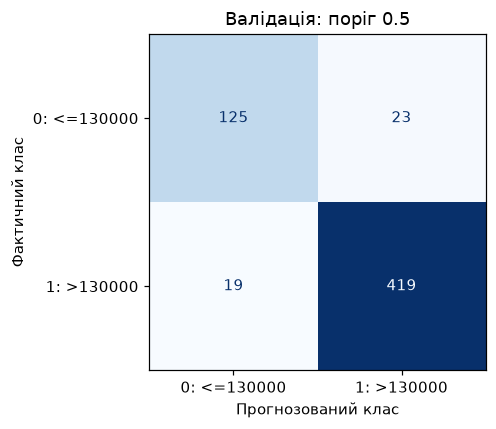

In [7]:
# ========= YOUR CODE STARTS HERE ========= #
valid_probabilities = model.predict(Z_valid[["const"] + selected])

def threshold_metrics(threshold):
    predicted = (valid_probabilities >= threshold).astype(int)
    matrix = confusion_matrix(y_valid, predicted, labels=[0, 1])
    tn, fp, fn, tp = matrix.ravel()
    metrics = {"Поріг": threshold, "TN": tn, "FP": fp, "FN": fn, "TP": tp,
               "Чутливість": tp / (tp + fn), "Специфічність": tn / (tn + fp),
               "Accuracy": (tp + tn) / matrix.sum(), "Прогнозів класу 1": predicted.sum()}
    return matrix, metrics

matrix_default, metrics_default = threshold_metrics(0.5)
display(pd.DataFrame(matrix_default, index=["Факт 0", "Факт 1"], columns=["Прогноз 0", "Прогноз 1"]))
display(pd.Series(metrics_default).to_frame("Значення"))
print("Accuracy постійного прогнозу класу 1:", y_valid.mean())
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(matrix_default, display_labels=["0: <=130000", "1: >130000"]).plot(ax=ax, colorbar=False, cmap="Blues")
ax.set(xlabel="Прогнозований клас", ylabel="Фактичний клас", title="Валідація: поріг 0.5")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "part3_confusion_default.png")
plt.show()
assert matrix_default.sum() == len(y_valid)

***Answer***

У матриці рядки відповідають фактичному класу, а стовпці прогнозованому. Чутливість дорівнює $TP/(TP+FN)$, специфічність $TN/(TN+FP)$, а загальна точність $(TP+TN)/N$. Тут $TP$ і $TN$ є кількостями правильних прогнозів класів 1 і 0, $FP$ і $FN$ кількостями хибних прогнозів цих класів, а $N$ кількістю валідаційних будинків.

- **TN (125).** Фактична ціна вкладається в бюджет 130000 доларів, і модель правильно визначила ці будинки як доступні за цим порогом.
- **FP (23).** Фактична ціна вкладається в бюджет, але модель спрогнозувала дорожчу групу. Покупець із таким бюджетом може помилково відкинути ці будинки.
- **FN (19).** Фактична ціна перевищує бюджет, але модель спрогнозувала доступну групу. Покупець може помилково очікувати, що ці будинки вкладаються в бюджет.
- **TP (419).** Фактична ціна перевищує бюджет, і модель правильно віднесла ці будинки до дорожчої групи.

За порогу 0.5 чутливість становить 0.9566, специфічність 0.8446, а загальна точність 0.9283.

### (е)

Оскільки поріг 0.5 не завжди є оптимальним, побудуйте ROC-криву за допомогою roc_curve та знайдіть площу під нею (roc_auc_score). Визначте оптимальний поріг класифікації, максимізувавши індекс Юдена (Sensitivity+Specificity−1). Побудуйте графік кривої за допомогою matplotlib.

,Значення
ROC AUC,0.97280328
Поріг Юдена,0.67279019
Індекс Юдена,0.84129335
Чутливість,0.92237443
Специфічність,0.91891892


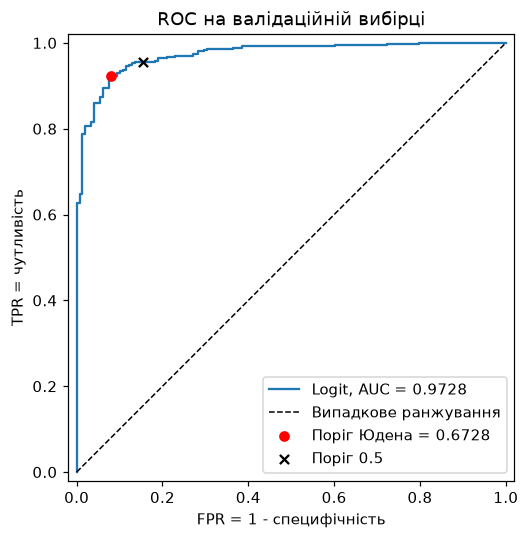

In [8]:
# ========= YOUR CODE STARTS HERE ========= #
fpr, tpr, thresholds = roc_curve(y_valid, valid_probabilities, drop_intermediate=False)
auc_value = roc_auc_score(y_valid, valid_probabilities)
youden = tpr - fpr
finite = np.flatnonzero(np.isfinite(thresholds))
# При однаковому максимумі беремо найбільший поріг: roc_curve повертає їх за спаданням.
best = finite[np.argmax(youden[finite])]
optimal_threshold = thresholds[best]
display(pd.Series({"ROC AUC": auc_value, "Поріг Юдена": optimal_threshold,
                   "Індекс Юдена": youden[best], "Чутливість": tpr[best],
                   "Специфічність": 1 - fpr[best]}).to_frame("Значення"))
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, label=f"Logit, AUC = {auc_value:.4f}")
ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Випадкове ранжування")
ax.scatter(fpr[best], tpr[best], color="red", label=f"Поріг Юдена = {optimal_threshold:.4f}", zorder=3)
ax.scatter(1 - metrics_default["Специфічність"], metrics_default["Чутливість"],
           marker="x", color="black", label="Поріг 0.5", zorder=3)
ax.set(xlabel="FPR = 1 - специфічність", ylabel="TPR = чутливість", title="ROC на валідаційній вибірці", xlim=(-0.02,1.02), ylim=(-0.02,1.02))
ax.legend(loc="lower right")
ax.set_aspect("equal")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "part3_roc.png")
plt.show()
assert 0 <= optimal_threshold <= 1
assert np.isclose(youden[best], youden[finite].max())

***Answer***

ROC показує, як чутливість і частка хибнопозитивних прогнозів змінюються з порогом. AUC є площею під цією кривою та характеризує, наскільки добре модель ранжує будинки двох класів.

Вибираємо поріг, що максимізує $J=\mathrm{TPR}-\mathrm{FPR}$. Тут $J$ є індексом Юдена, $\mathrm{TPR}$ чутливістю, а $\mathrm{FPR}$ часткою хибнопозитивних прогнозів серед будинків класу 0. Оскільки $\mathrm{FPR}$ дорівнює одиниці мінус специфічність, цей критерій дає однакову вагу чутливості та специфічності.

AUC на валідаційній вибірці становить 0.9728. Найбільший індекс Юдена 0.8413 отримали за порогу 0.6728. Оскільки поріг вибрано на цій самій вибірці, метрики за ним описують результат на даних, використаних для вибору порогу.

### (ж)

Перерахуйте матрицю помилок, чутливість та специфічність для нового (оптимального за ROC) порогу. Порівняйте ці метрики з отриманими при порозі 0.5. Дайте відповідь: чи стала ваша модель після зміни порогу більш «консервативною» щодо прогнозування дорогих будинків (клас 1)?

,Поріг,TN,FP,FN,TP,Чутливість,Специфічність,Accuracy,Прогнозів класу 1
Стандартний,0.5,125,23,19,419,0.956621,0.84459459,0.92832765,442
За Юденом,0.67279019,136,12,34,404,0.92237443,0.91891892,0.92150171,416


,Прогноз 0,Прогноз 1
Факт 0,136,12
Факт 1,34,404


Зміна кількості прогнозів класу 1: -26
Поріг підвищився: True


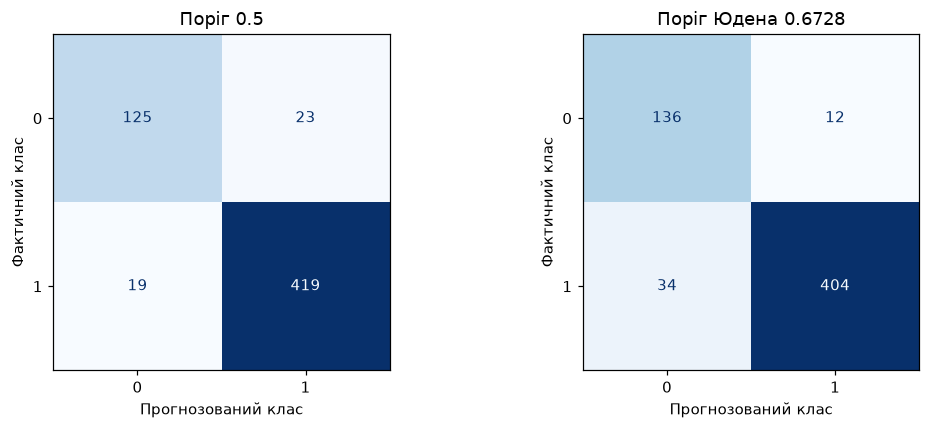

In [9]:
# ========= YOUR CODE STARTS HERE ========= #
matrix_optimal, metrics_optimal = threshold_metrics(optimal_threshold)
comparison = pd.DataFrame([metrics_default, metrics_optimal], index=["Стандартний", "За Юденом"])
display(comparison)
display(pd.DataFrame(matrix_optimal, index=["Факт 0", "Факт 1"], columns=["Прогноз 0", "Прогноз 1"]))
print("Зміна кількості прогнозів класу 1:", metrics_optimal["Прогнозів класу 1"] - metrics_default["Прогнозів класу 1"])
print("Поріг підвищився:", optimal_threshold > 0.5)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, matrix, title in zip(axes, [matrix_default, matrix_optimal], ["Поріг 0.5", f"Поріг Юдена {optimal_threshold:.4f}"]):
    ConfusionMatrixDisplay(matrix, display_labels=[0, 1]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set(xlabel="Прогнозований клас", ylabel="Фактичний клас", title=title)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "part3_confusion_comparison.png")
plt.show()
assert np.isclose(metrics_optimal["Чутливість"], tpr[best])
assert np.isclose(1 - metrics_optimal["Специфічність"], fpr[best])
assert np.all(matrix_default.sum(axis=1) == matrix_optimal.sum(axis=1))
assert metrics_optimal["Чутливість"] + metrics_optimal["Специфічність"] >= metrics_default["Чутливість"] + metrics_default["Специфічність"] - 1e-12

***Answer***

Змінюємо лише поріг перетворення ймовірності на клас. За вищого порогу моделі потрібна більша прогнозована ймовірність, щоб віднести будинок до класу 1.

Правило стало більш консервативним щодо дорогих будинків. Поріг зріс із 0.5 до 0.6728, і кількість прогнозів класу 1 зменшилася з 442 до 416. Хибнопозитивних прогнозів стало 12 замість 23, а хибнонегативних 34 замість 19. Специфічність зросла з 0.8446 до 0.9189, а чутливість зменшилася з 0.9566 до 0.9224. Модель рідше помилково називає доступний будинок дорогим, але частіше пропускає справді дорогі будинки.